# Métricas do Dashboard 2: testes antes do app

Notebook da Aula 22 (*Como planejar métricas*): antes de levar os KPIs para o `app.py`, cada métrica é
calculada aqui com pandas, comparada entre grupos e visualizada num plot prévio. Só depois de validada
ela vira um `st.metric` no app.

Fluxo seguido: **seleção de variáveis → proposição de métricas → elaboração de visualizações**.

- Base: `data/clean/dataset.csv`, exportado no final de `eda-com-downloads.ipynb` (20.000 veículos,
  ausentes já imputados na EDA).
- Público-alvo: gestão de manutenção de uma frota (ou equipe de garantia de baterias) que precisa decidir
  quais veículos mandar primeiro para inspeção preventiva.
- Justificativa completa de cada métrica: `entregas/justificativa-metricas.md`.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", message=".*N > 5000.*")  # aviso do Shapiro em amostras grandes

RAIZ = Path("..") if Path("../data").exists() else Path(".")
sys.path.insert(0, str(RAIZ.resolve()))  # para importar src/ e conferir o cálculo do app

sns.set_theme(style="whitegrid")
COR_NORMAL, COR_FALHA = "#d4789a", "#5e3e93"  # mesma identidade visual do app

df = pd.read_csv(RAIZ / "data" / "clean" / "dataset.csv")
VARS_QUANT = ["state_of_health", "cycle_count", "internal_resistance", "capacity_loss_percent", "thermal_runaway_risk"]
df.shape

(20000, 73)

## 1. Seleção de variáveis

A EDA (Seção 6) mostrou que todas as 5 quantitativas diferem entre Normal e Falha (Mann-Whitney com
p ≈ 0, esperado com n = 20.000). Com uma amostra desse tamanho o p-valor quase não discrimina, então aqui
olhamos o **tamanho** da diferença entre as medianas:

In [2]:
medianas = df.groupby("status_bateria")[VARS_QUANT].median().T
medianas["diferenca_relativa"] = (medianas["Falha"] - medianas["Normal"]) / medianas["Normal"]
medianas.round(3)

status_bateria,Falha,Normal,diferenca_relativa
state_of_health,71.660,82.960,-0.136
cycle_count,1498.500,1295.000,0.157
internal_resistance,0.624,0.427,0.463
capacity_loss_percent,28.255,16.985,0.664
thermal_runaway_risk,40.595,14.210,1.857


In [3]:
# Qualitativas candidatas: taxa de falha por categoria e teste Qui-quadrado
for col in ["faixa_idade_veiculo", "battery_chemistry", "fleet_or_private", "vehicle_type", "terrain_type"]:
    tabela = pd.crosstab(df[col], df["battery_failure"])
    p = stats.chi2_contingency(tabela).pvalue
    taxa = df.groupby(col)["battery_failure"].mean().round(3).to_dict()
    print(f"{col:20s} Qui² p-valor={p:.2g} | taxa de falha: {taxa}")

faixa_idade_veiculo  Qui² p-valor=5.9e-205 | taxa de falha: {'4-6 anos': 0.034, '7-8 anos': 0.084, '9+ anos': 0.158, '<4 anos': 0.013}
battery_chemistry    Qui² p-valor=0.41 | taxa de falha: {'LFP': 0.067, 'LMO': 0.072, 'LTO': 0.06, 'NCA': 0.065, 'NMC': 0.072}
fleet_or_private     Qui² p-valor=0.61 | taxa de falha: {'Fleet': 0.071, 'Private': 0.069}
vehicle_type         Qui² p-valor=0.54 | taxa de falha: {'Crossover': 0.067, 'Hatchback': 0.072, 'SUV': 0.063, 'Sedan': 0.073, 'Truck': 0.067, 'Van': 0.073}
terrain_type         Qui² p-valor=0.92 | taxa de falha: {'Coastal': 0.07, 'Desert': 0.072, 'Flat': 0.067, 'Hilly': 0.067, 'Mountainous': 0.069}


**Decisão:**

- `state_of_health` (SoH) e `thermal_runaway_risk` são as que mais separam as classes e **não se
  correlacionam entre si** (Spearman −0,05 na EDA). São dois sinais independentes de risco, então as
  duas entram nos KPIs.
- `capacity_loss_percent` e `internal_resistance` ficam fora dos KPIs por **redundância**: correlação de
  −0,94 e −0,86 com o SoH. Elas contam a mesma história (degradação) e continuam no Dashboard 1.
- `faixa_idade_veiculo` tem a associação mais forte entre as qualitativas e vira o gráfico de barras
  principal.
- Química, tipo de uso, tipo de veículo e terreno **não** têm associação com falha (p > 0,4). A química
  entra num gráfico justamente para mostrar isso ao público, que tende a supor que ela importa.

## 2. Proposição e cálculo das métricas

| # | Métrica | Tipo (aula de métricas) | Variável |
|---|---|---|---|
| 1 | Veículos no recorte | Contagem | linhas do recorte |
| 2 | Taxa de falha | Proporção / taxa | `battery_failure` |
| 3 | SoH mediano | Medida central (mediana) | `state_of_health` |
| 4 | Risco térmico extremo | Proporção acima de um limite | `thermal_runaway_risk` > 53,92 |

O limite 53,92 é o limite superior do IQR calculado na EDA (Seção 4), antes da imputação. Nos cards, cada
métrica vem com a **variação** em relação à base completa (p.p.).

In [4]:
LIMITE_RISCO = 53.92  # limite superior do IQR de thermal_runaway_risk (EDA, Seção 4)


def kpis(dados):
    return pd.Series({
        "veiculos": len(dados),
        "taxa_falha": dados["battery_failure"].mean(),
        "soh_mediano": dados["state_of_health"].median(),
        "risco_extremo": (dados["thermal_runaway_risk"] > LIMITE_RISCO).mean(),
    })

base = kpis(df)
base

veiculos         20000.0000
taxa_falha           0.0692
soh_mediano         82.8800
risco_extremo        0.0350
dtype: float64

### Por que mediana no SoH, e por que o limite do IQR no risco térmico?

O Shapiro-Wilk rejeitou a normalidade das duas variáveis na EDA. O SoH tem assimetria negativa, então a
mediana é mais robusta que a média. No risco térmico (assimetria 1,38), os outliers pelo IQR foram
**mantidos** na EDA porque deviam ser justamente as baterias em falha. Conferindo essa hipótese:

In [5]:
acima = df["thermal_runaway_risk"] > LIMITE_RISCO
print(f"Veículos acima do limite: {acima.sum()} ({acima.mean():.1%} da base)")
print(f"Taxa de falha acima do limite: {df.loc[acima, 'battery_failure'].mean():.1%}")
print(f"Taxa de falha no restante:     {df.loc[~acima, 'battery_failure'].mean():.1%}")
print(f"SoH: média = {df['state_of_health'].mean():.2f} | mediana = {df['state_of_health'].median():.2f} | "
      f"assimetria = {df['state_of_health'].skew():.2f}")

Veículos acima do limite: 700 (3.5% da base)
Taxa de falha acima do limite: 47.4%
Taxa de falha no restante:     5.5%
SoH: média = 81.93 | mediana = 82.88 | assimetria = -0.49


### Testando as métricas em recortes (simulando os filtros do app)

In [6]:
recortes = {
    "Base completa": df,
    "Frota": df[df["fleet_or_private"] == "Fleet"],
    "Particular": df[df["fleet_or_private"] == "Private"],
    "9+ anos": df[df["faixa_idade_veiculo"] == "9+ anos"],
    "<4 anos": df[df["faixa_idade_veiculo"] == "<4 anos"],
    "SoH < 70% e risco > 50": df[(df["state_of_health"] < 70) & (df["thermal_runaway_risk"] > 50)],
    "Recorte vazio": df[df["state_of_health"] > 200],
}
tabela = pd.DataFrame({nome: kpis(dados) for nome, dados in recortes.items()}).T
tabela["delta_falha_pp"] = (tabela["taxa_falha"] - base["taxa_falha"]) * 100
tabela.round(3)

,veiculos,taxa_falha,soh_mediano,risco_extremo,delta_falha_pp
Base completa,20000.0,0.069,82.88,0.035,0.000
Frota,6748.0,0.071,82.88,0.034,0.134
Particular,13252.0,0.069,82.88,0.036,-0.068
9+ anos,4770.0,0.158,73.46,0.036,8.887
<4 anos,4824.0,0.013,90.70,0.032,-5.635
SoH < 70% e risco > 50,123.0,0.846,66.45,0.683,77.633
Recorte vazio,0.0,NaN,NaN,NaN,NaN


O recorte vazio dá `NaN` nas proporções e na mediana. No app isso aparece como "—" no card, sem erro.

### Conferência: o cálculo do app (`src/metricas.py`) bate com o do notebook?

In [7]:
from src.metricas import resumo_kpis, taxa_por_grupo

for nome, dados in recortes.items():
    app = pd.Series(resumo_kpis(dados, LIMITE_RISCO))
    nb = kpis(dados)
    assert np.allclose(app.astype(float), nb.astype(float), equal_nan=True), nome
print("Os 4 KPIs do app conferem com o notebook em todos os recortes.")
taxa_por_grupo(df, "faixa_idade_veiculo", ["<4 anos", "4-6 anos", "7-8 anos", "9+ anos"])

Os 4 KPIs do app conferem com o notebook em todos os recortes.


,faixa_idade_veiculo,veiculos,falhas,taxa,taxa_texto
0,<4 anos,4824,62,0.012852,"1,3%"
1,4-6 anos,5791,195,0.033673,"3,4%"
2,7-8 anos,3847,324,0.084221,"8,4%"
3,9+ anos,4770,754,0.158071,"15,8%"


## 3. Plots prévios das visualizações

Rascunho com seaborn dos 3 visuais do Dashboard 2. No app eles foram refeitos em Altair, com seleção cruzada.

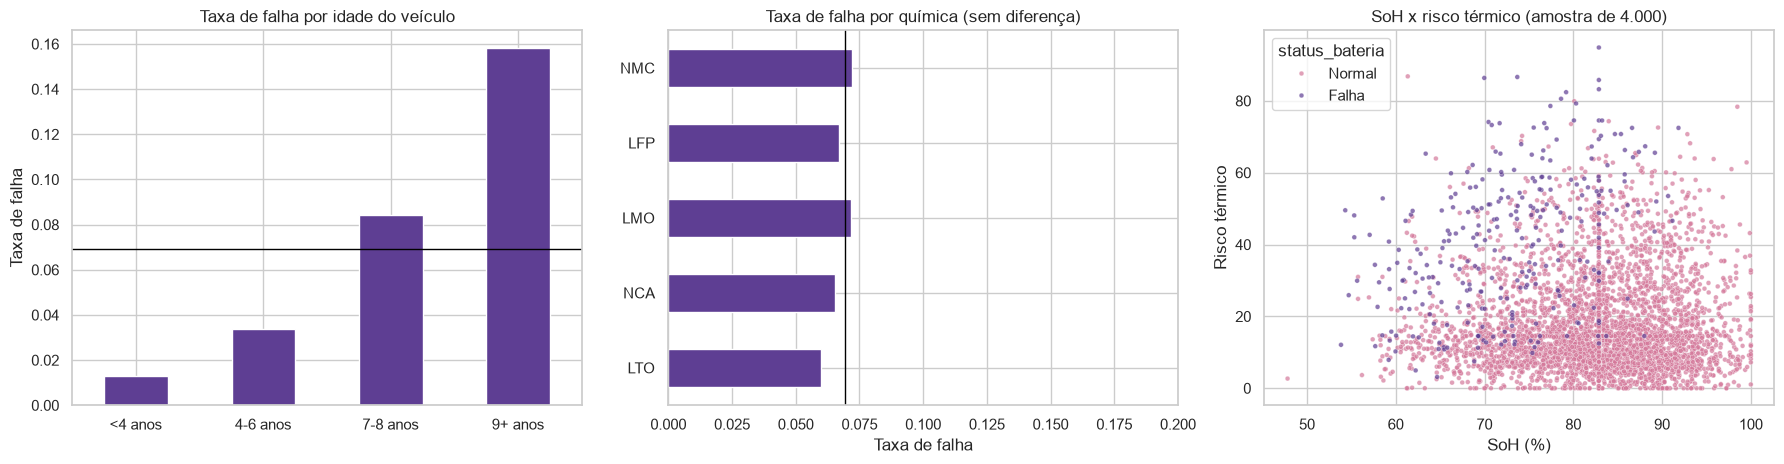

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

taxa_idade = df.groupby("faixa_idade_veiculo")["battery_failure"].mean().reindex(["<4 anos", "4-6 anos", "7-8 anos", "9+ anos"])
taxa_idade.plot(kind="bar", color=COR_FALHA, ax=axes[0])
axes[0].axhline(base["taxa_falha"], color="black", linewidth=1)
axes[0].set(title="Taxa de falha por idade do veículo", ylabel="Taxa de falha", xlabel="")
axes[0].tick_params(axis="x", rotation=0)

taxa_quimica = df.groupby("battery_chemistry")["battery_failure"].mean().reindex(["NMC", "LFP", "LMO", "NCA", "LTO"])
taxa_quimica.plot(kind="barh", color=COR_FALHA, ax=axes[1])
axes[1].axvline(base["taxa_falha"], color="black", linewidth=1)
axes[1].set(title="Taxa de falha por química (sem diferença)", xlabel="Taxa de falha", ylabel="", xlim=(0, 0.2))
axes[1].invert_yaxis()

amostra = df.sample(4000, random_state=42).sort_values("battery_failure")
sns.scatterplot(data=amostra, x="state_of_health", y="thermal_runaway_risk", hue="status_bateria",
                palette={"Normal": COR_NORMAL, "Falha": COR_FALHA}, s=12, alpha=0.7, ax=axes[2])
axes[2].set(title="SoH x risco térmico (amostra de 4.000)", xlabel="SoH (%)", ylabel="Risco térmico")

plt.tight_layout()
plt.show()

In [9]:
# A "zona de falha": taxa de falha cruzando faixas de SoH e de risco térmico
pd.crosstab(
    pd.cut(df["state_of_health"], [0, 70, 80, 90, 101], labels=["≤70", "70-80", "80-90", ">90"]),
    pd.cut(df["thermal_runaway_risk"], [-1, 15, 30, 50, 101], labels=["≤15", "15-30", "30-50", ">50"]),
    values=df["battery_failure"], aggfunc="mean",
).round(3)

thermal_runaway_risk,≤15,15-30,30-50,>50
state_of_health,,,,
≤70,0.112,0.257,0.556,0.846
70-80,0.018,0.061,0.236,0.596
80-90,0.004,0.009,0.071,0.355
>90,0.000,0.002,0.011,0.075


## Conclusões para o Dashboard 2

1. A taxa de falha da base é 6,9%, mas cresce com a idade do veículo: 1,3% abaixo de 4 anos e 15,8% com
   9 anos ou mais.
2. SoH baixo e risco térmico alto são sinais **independentes**, e juntos concentram as falhas: com SoH ≤ 70%
   e risco > 50, a taxa de falha passa de 80%; com SoH > 90% e risco ≤ 15, fica perto de zero.
3. Os 3,5% de veículos acima do limite IQR de risco térmico têm 47% de falha. Isso confirma a decisão da EDA
   de manter esses outliers.
4. Química, tipo de uso, tipo de veículo e terreno não mudam a taxa de falha. Para o público, esse "não
   importa" também é um resultado: evita priorizar inspeções pelo critério errado.